# Занятие 05. Локальные объяснения: LIME, SHAP и мост к нейросетям — демо и конспект

Этот ноутбук можно читать без занятия: перед каждым фрагментом кода есть

- **Блок «Теория»** — что делает метод, формулы и пример;
- **Как устроен код** — тот же код на псевдоязыке, шаг за шагом;
- **В чём измеряется** — единицы того, что вывел код;
- **На что обращать внимание** — нюансы работы и границы метода, каждый с примером на этих данных.

Сквозной сюжет: банк отказал клиенту в кредите. Вопросы к одному прогнозу:

1. **LIME** — какая простая модель ведёт себя как наша рядом с этим клиентом?
2. **SHAP** — как честно разделить прогноз между признаками?
3. **CAM и attention** — что нейросеть хранит по определению архитектуры: карты признаков свёрточной сети и веса внимания трансформера; что они показывают и в чём их минусы.
4. **Градиенты** — объяснение всей модели через вход для любой дифференцируемой модели: что остаётся от LIME и SHAP, если у модели есть производная.

«Что изменить, чтобы решение поменялось» (контрфактуалы) и якоря — на занятии 04.

**Связь с занятием 04.** Методы 04 извлекали характеристики признаков (кривые, осцилляции, изменение метрики) без требований к самому методу. SHAP — первый метод курса, заданный аксиомами. Выбор фона в SHAP и baseline в IG — тот же вопрос, что у перестановки и других методов на основе вмешательства: чем заменить признак, чтобы это означало «его нет».

Всё считается на CPU за 1–2 минуты. Окружение — `requirements.txt` курса.

> Данные — German Credit, а не California Housing и не ирисы: на тех датасетах построены практические блоки Stepik (ДЗ-1). Код отсюда к ним переносится, ответы — нет.

## Библиотеки и почему именно они

| Библиотека | Зачем здесь | Почему она |
|---|---|---|
| `scikit-learn` | градиентный бустинг, логистическая регрессия, permutation importance | единый интерфейс `fit` / `predict_proba`; бустинг из sklearn поддерживается `shap.TreeExplainer` в режиме `interventional` |
| `lime` | `LimeTabularExplainer` | реализация авторов метода (Ribeiro et al., 2016). Пакет заморожен с 2020 года, но остаётся эталоном, с которым сравнивают все варианты LIME |
| `shap` | `TreeExplainer`, `LinearExplainer` | библиотека авторов SHAP (Lundberg & Lee, 2017): точный полиномиальный алгоритм для деревьев и много объяснителей с одним интерфейсом |
| `numpy`, `pandas`, `matplotlib` | Kernel SHAP и Integrated Gradients своими руками, графики | чтобы увидеть, что внутри методов нет магии |
| `torch`, `transformers` | маленькая сеть, GPT-2 | градиенты одним `backward`; ResNet-34 для CAM, GPT-2 small — небольшая открытая языковая модель |

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from itertools import combinations, permutations
from math import comb, factorial
import shap
from lime.lime_tabular import LimeTabularExplainer
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score
plt.rcParams["figure.dpi"] = 110

---
# Часть 0. Данные, модель и клиент

**Данные.** German Credit (UCI Statlog, OpenML `credit-g`): 1000 заёмщиков немецкого банка 1970-х, 20 признаков — состояние счёта, срок и сумма кредита, кредитная история, цель, сбережения, стаж, возраст и т. д. Цель — вернул ли клиент кредит (`good` / `bad`); `bad` — 30 %.

**Кодирование.** Категориальные признаки переводим в целые коды. У четырёх признаков есть естественный порядок (счёт, история, сбережения, стаж) — задаём его явно, остальные кодируем по алфавиту. Деревьям этого достаточно: разбиение по порогу кода — это разбиение на группы категорий.

**Модель.** Градиентный бустинг, 300 деревьев глубины 3. Прогноз — вероятность невозврата $p(x)$; «отказ», если $p \ge 0{,}5$.

In [2]:
d = fetch_openml("credit-g", version=1, as_frame=True).frame
ORDER = {
    "checking_status": ["<0", "0<=X<200", ">=200", "no checking"],
    "credit_history": ["no credits/all paid", "all paid", "existing paid", "delayed previously", "critical/other existing credit"],
    "savings_status": ["<100", "100<=X<500", "500<=X<1000", ">=1000", "no known savings"],
    "employment": ["unemployed", "<1", "1<=X<4", "4<=X<7", ">=7"],
}
X = d.drop(columns="class").copy()
cats = list(X.select_dtypes("category").columns)
CODES = {}
for c in cats:
    CODES[c] = ORDER.get(c, list(X[c].cat.categories))
    X[c] = np.asarray(X[c].astype(str).map({v: i for i, v in enumerate(CODES[c])}), dtype=int)
X = X.astype(float)
y = (d["class"] == "bad").astype(int).values          # 1 = клиент не вернул кредит
feat = list(X.columns); F = len(feat)

Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, random_state=0, stratify=y)
gbm = GradientBoostingClassifier(n_estimators=300, max_depth=3, learning_rate=0.05, subsample=0.8, random_state=0).fit(Xtr, ytr)
f = lambda A: gbm.predict_proba(np.asarray(A, dtype=float))[:, 1]
def logit(q): q = np.clip(q, 1e-9, 1 - 1e-9); return np.log(q / (1 - q))
def readable(j, v): return CODES[feat[j]][int(v)] if feat[j] in cats else f"{v:g}"

p_te = f(Xte)
print(f"ROC-AUC на тесте: {roc_auc_score(yte, p_te):.3f};  отказов в тесте: {(p_te >= .5).sum()} из {len(yte)}")

ROC-AUC на тесте: 0.772;  отказов в тесте: 56 из 250


In [3]:
I0 = 11                       # клиент, которого объясняем весь ноутбук
x0 = Xte.iloc[I0].values
p0 = f(x0[None])[0]
print(f"p(невозврат) = {p0:.3f}  → отказ")
pd.Series({feat[j]: readable(j, x0[j]) for j in range(F)}, name="клиент").to_frame()

p(невозврат) = 0.827  → отказ


,клиент
checking_status,0<=X<200
duration,60
credit_history,existing paid
purpose,new car
credit_amount,7408
savings_status,100<=X<500
employment,<1
installment_commitment,4
personal_status,female div/dep/mar
other_parties,none


Клиентке 24 года, она просит 7408 марок на новую машину на 60 месяцев, стаж меньше года. Модель оценивает риск невозврата в 83 % и отказывает. Почему?

---
# Часть 1. LIME: локальный суррогат

## 1.1. Идея на игрушке

### Блок «Теория»

**Вопрос LIME:** какая *простая* модель ведёт себя как наша *рядом с* объектом $x$?

$$\xi(x) = \arg\min_{g \in G}\; \underbrace{\sum_{z} \pi_x(z)\,\big(f(z) - g(z')\big)^2}_{L(f,\,g,\,\pi_x)} + \Omega(g), \qquad \pi_x(z) = \exp\!\Big(-\frac{D(x,z)^2}{\sigma^2}\Big).$$

- $f$ — чёрный ящик; $G$ — семейство простых моделей (обычно линейные);
- $z$ — возмущённые объекты, $z'$ — их интерпретируемое представление (например, «признак в том же интервале, что у $x$: да/нет»);
- $\pi_x$ — вес близости: точки рядом с $x$ важнее; $\sigma$ — **ширина ядра**;
- $\Omega(g)$ — штраф за сложность; в LIME — не больше $K$ ненулевых весов (K-Lasso).

Объяснение — веса $g$. Это **модель**, а не разложение прогноза: сумма весов не обязана равняться $f(x)$.

**Пример.** Граница решений модели — изогнутая кривая. Глобально прямой её не описать, но в малой окрестности $x$ она почти прямая; LIME находит эту прямую.

### Как устроен код
```
выбрать x; сгенерировать z равномерно по квадрату
вес π = exp(−‖z − x‖² / σ²)
g ← взвешенная линейная регрессия f(z) на (z − x)
наклоны g — объяснение; меняем σ и смотрим, как они меняются
```

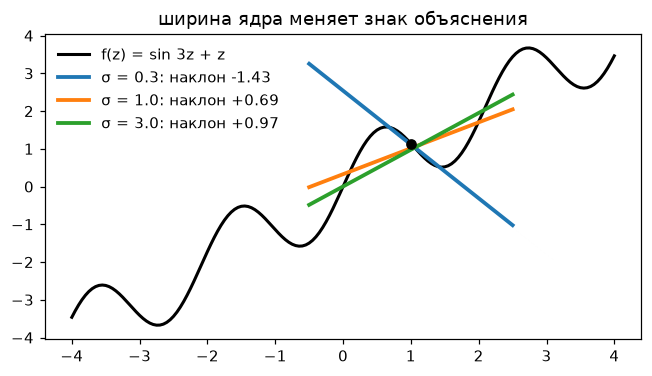

In [4]:
fz = lambda z: np.sin(3 * z) + z          # одномерный «чёрный ящик»
x1d = 1.0
zs = np.linspace(-4, 4, 161)
def lime_1d(sigma):
    w = np.exp(-(zs - x1d) ** 2 / sigma ** 2)
    D = np.c_[np.ones_like(zs), zs - x1d]
    return np.linalg.solve(D.T @ (D * w[:, None]), D.T @ (w * fz(zs)))   # [β0, наклон]

plt.figure(figsize=(7, 3.6)); plt.plot(zs, fz(zs), "k", lw=2, label="f(z) = sin 3z + z")
for sigma in [0.3, 1.0, 3.0]:
    b0, b1 = lime_1d(sigma); zz = np.linspace(x1d - 1.5, x1d + 1.5, 5)
    plt.plot(zz, b0 + b1 * (zz - x1d), lw=2.5, label=f"σ = {sigma}: наклон {b1:+.2f}")
plt.scatter([x1d], [fz(x1d)], color="k", zorder=5); plt.legend(frameon=False); plt.title("ширина ядра меняет знак объяснения");

**В чём измеряется.** Наклон суррогата — изменение $f$ на единицу $z$.

### На что обращать внимание

- **Ответ зависит от ширины ядра.** Узкое ядро описывает $f$ в малой окрестности, широкое — средний наклон на большом диапазоне. Здесь в точке $x = 1$ наклон $-1{,}43$ при $\sigma = 0{,}3$ и $+0{,}97$ при $\sigma = 3$.
- **Правила выбора $\sigma$ нет.** В `lime` по умолчанию $\sigma = 0{,}75\sqrt{d}$ — эвристика: при другом числе признаков та же точка получает другую окрестность.
- **Ядро в `lime` шире, чем в статье.** Библиотека берёт корень: $\sqrt{\exp(-D^2/\sigma^2)} = \exp\big(-D^2/(2\sigma^2)\big)$, то есть ширина в $\sqrt 2$ раз больше той же $\sigma$ в формуле статьи.

## 1.2. LIME на клиенте: представление меняет ответ

### Блок «Теория»

Как `LimeTabularExplainer` строит окрестностб:

1. **С дискретизацией** (`discretize_continuous=True`, по умолчанию). Каждый числовой признак режется на квартили по обучающей выборке. Сэмплы $z$ генерируются **из распределения обучающих данных**, а не вокруг $x$. Интерпретируемое представление $z'_j = 1$, если $z_j$ попал в тот же квартиль (ту же категорию), что и $x_j$. Близость считается в пространстве $z'$. Вес — «насколько прогноз выше, когда признак в том же интервале, что у клиента, а не в случайном».
2. **Без дискретизации** (`discretize_continuous=False`, `sample_around_instance=True`): $z = x + \varepsilon$, $\varepsilon \sim \mathcal N(0, \sigma_{\text{train}}^2)$ — гауссов шум вокруг $x$; веса — наклоны в стандартизованных единицах.

Это **два разных вопроса** к одной модели. Ответы могут не совпасть — это ок.

### Как устроен код
```
для режима в [с дискретизацией, без]:
    lime ← LimeTabularExplainer(обучающая выборка, категориальные признаки, режим)
    объяснение ← lime.explain_instance(x0, model.predict_proba, 5000 сэмплов)
    вывести топ признаков и R² суррогата (explanation.score)
```

In [5]:
cat_idx = [feat.index(c) for c in cats]
def lime_run(seed, n, disc, kw=None):
    le = LimeTabularExplainer(Xtr.values, feature_names=feat, categorical_features=cat_idx, class_names=["good", "bad"],
                              discretize_continuous=disc, sample_around_instance=not disc, kernel_width=kw, random_state=seed)
    e = le.explain_instance(x0, lambda Z: gbm.predict_proba(Z), num_features=F, num_samples=n)
    w = dict(e.as_map()[1])
    return pd.Series([w.get(j, 0.0) for j in range(F)], index=feat), e

w_disc, e_disc = lime_run(0, 5000, True)
w_cont, e_cont = lime_run(0, 5000, False)
print("С дискретизацией, R² суррогата =", round(e_disc.score, 2))
for rule, w in e_disc.as_list()[:5]: print(f"   {rule:28s} {w:+.3f}")
print("Без дискретизации, R² суррогата =", round(e_cont.score, 2))
print(w_cont.sort_values(key=np.abs, ascending=False).head(5).round(3).to_string())

С дискретизацией, R² суррогата = 0.2
   duration > 24.00             +0.147
   credit_amount > 3866.75      +0.106
   checking_status=1            +0.084
   purpose=1                    +0.082
   other_payment_plans=1        -0.081
Без дискретизации, R² суррогата = 0.41
age                   -0.169
foreign_worker         0.101
credit_amount          0.060
other_payment_plans   -0.056
purpose                0.055


**В чём измеряется.** С дискретизацией вес — изменение вероятности невозврата, когда признак в том же интервале (категории), что у клиентки, по сравнению со случайным значением из обучающей выборки. Без дискретизации — изменение вероятности на одно стандартное отклонение признака. R² суррогата — доля дисперсии прогнозов в окрестности, объяснённая линейной моделью.

### На что обращать внимание

- **Представление и окрестность задают вопрос.** С дискретизацией сравнивают «значение как у объекта» со «значением случайного объекта выборки», без неё — малый гауссов сдвиг всех признаков сразу. Здесь лидер в первом случае — срок кредита (`duration > 24`, $+0{,}15$), во втором — возраст ($-0{,}17$).
- **Локальная точность суррогата бывает низкой.** Объяснение описывает $f$ настолько, насколько суррогат на неё похож. Здесь R² суррогата 0,20 и 0,41: линейная модель описывает меньше половины поведения $f$ в окрестности.
- **С дискретизацией окрестность не локальна в исходном пространстве.** Сэмплы берутся из распределения всей выборки, близость считается в пространстве бинарных $z'$.
- **Веса — не разложение прогноза.** Сумма весов не равна ни $f(x)$, ни $f(x) - \mathbb E f$.

## 1.3. Нестабильность — небольшой чек

### Блок «Теория»

Окрестность сэмплируется случайно, поэтому веса LIME — оценка по случайной выборке: при другом seed в общем случае могут быть другие веса. Разброс оценки убывает с числом сэмплов, компонента смещение от выбора ядра и представления — нет.

**Оценка и её предел.** LIME по $n$ сэмплам решает взвешенную регрессию: $\hat\beta_n = (Z^\top W Z)^{-1} Z^\top W\, f(Z)$, где строки $Z$ — представления $z'_k$, $W = \mathrm{diag}\big(\pi_x(z_k)\big)$. При $n \to \infty$ оценка сходится к решению той же задачи на всём распределении сэмплов:
$$\beta^*(\sigma) = A^{-1}\,\mathbb E\big[\pi_x(z)\, z' f(z)\big], \qquad A = \mathbb E\big[\pi_x(z)\, z' z'^\top\big].$$

**Разброс** (сэндвич-оценка взвешенного МНК):
$$\mathrm{Var}(\hat\beta_n) \approx \frac1n\, A^{-1} B A^{-1}, \qquad B = \mathbb E\big[\pi_x(z)^2\, r(z)^2\, z' z'^\top\big], \quad r(z) = f(z) - \beta^{*\top} z'.$$
Стандартное отклонение весов убывает как $1/\sqrt n$. Оно больше, когда суррогат плохо описывает $f$ (большие остатки $r$, низкий R²) и когда вес $\pi_x$ сосредоточен на немногих сэмплах.

**Смещение** относительно локального наклона $\nabla f(x)$ от $n$ не зависит. Для одного признака и симметричной окрестности разложение Тейлора даёт
$$\beta^*(\sigma) = f'(x) + \frac{f'''(x)}{2}\, s^2 + \frac{f^{(5)}(x)}{8}\, s^4 + O(s^6),$$
где $s^2$ — дисперсия эффективной окрестности; для ядра $\exp(-t^2/\sigma^2)$ на равномерных сэмплах $s^2 = \sigma^2/2$. Чётные производные не входят: их вклад в наклон при симметричных весах сокращается.

В `lime` вместо МНК — гребневая регрессия с $\alpha = 1$; при тысячах сэмплов штраф почти не меняет оценку.

### Как устроен код
```
для n в [300, 5000]:
    20 раз: LIME с разным random_state → вектор весов
    сколько различных наборов топ-3 признаков? как часто меняется лидер?
разброс: std весов по 20 запускам при n = 300 и n = 5000; отношение против √(5000/300)
смещение: наклон 1D-игрушки из 1.1 при разных σ против f′ + f‴s²/2 + f⁽⁵⁾s⁴/8
```

In [6]:
Ws = {}
for n in [300, 5000]:
    W = Ws[n] = pd.DataFrame([lime_run(s, n, True)[0] for s in range(20)])
    top3 = {tuple(sorted(w.abs().nlargest(3).index)) for _, w in W.iterrows()}
    leaders = W.abs().idxmax(axis=1).value_counts().to_dict()
    print(f"n = {n}: разных топ-3 = {len(top3)} из 20; лидеры: {leaders}")

n = 300: разных топ-3 = 8 из 20; лидеры: {'duration': 15, 'employment': 2, 'foreign_worker': 1, 'credit_amount': 1, 'checking_status': 1}


n = 5000: разных топ-3 = 3 из 20; лидеры: {'duration': 20}


In [7]:
sd = {n: W.std().mean() for n, W in Ws.items()}             # средний по признакам разброс веса между запусками
print(f"std весов: n = 300 — {sd[300]:.4f}, n = 5000 — {sd[5000]:.4f};  отношение {sd[300] / sd[5000]:.2f}, теория √(5000/300) = {np.sqrt(5000 / 300):.2f}")

d1, d3, d5 = 1 + 3 * np.cos(3 * x1d), -27 * np.cos(3 * x1d), 243 * np.cos(3 * x1d)   # производные sin 3z + z в x = 1
rows = []
for sigma in [0.1, 0.3, 0.5, 1.0]:
    s2 = sigma ** 2 / 2
    rows.append({"σ": sigma, "наклон LIME": lime_1d(sigma)[1], "f′ + f‴s²/2": d1 + d3 * s2 / 2, "+ f⁽⁵⁾s⁴/8": d1 + d3 * s2 / 2 + d5 * s2 ** 2 / 8})
print(f"f′(1) = {d1:.3f} — предел при σ → 0")
pd.DataFrame(rows).round(3)

std весов: n = 300 — 0.0309, n = 5000 — 0.0081;  отношение 3.83, теория √(5000/300) = 4.08
f′(1) = -1.970 — предел при σ → 0


,σ,наклон LIME,f′ + f‴s²/2,+ f⁽⁵⁾s⁴/8
0,0.1,-1.904,-1.903,-1.904
1,0.3,-1.426,-1.369,-1.429
2,0.5,-0.692,-0.299,-0.769
3,1.0,0.687,4.712,-2.805


**В чём измеряется.** Число различных наборов из трёх главных признаков в 20 запусках; лидер — признак с наибольшим модулем веса. Разброс — стандартное отклонение веса между запусками, усреднённое по признакам, в единицах вероятности. Наклон 1D-игрушки — изменение $f$ на единицу $z$.

### На что обращать внимание

- **Объяснение LIME случайно.** При малом числе сэмплов меняется даже набор главных признаков. Здесь при 300 сэмплах 20 запусков дают 8 разных топ-3, при 5000 — 3.
- **Разброс убывает как $1/\sqrt n$.** Здесь переход от 300 к 5000 сэмплам уменьшает стандартное отклонение весов в 3,83 раза при теоретических $\sqrt{5000/300} = 4{,}08$; остаток — гребневый штраф и конечное число запусков.
- **Смещение от числа сэмплов не зависит, оно задаётся шириной окрестности.** На игрушке из 1.1 предел при $\sigma \to 0$ — $f'(1) = -1{,}97$; при $\sigma = 0{,}3$ LIME даёт $-1{,}43$, разложение $f' + f'''s^2/2 + f^{(5)}s^4/8$ — тоже $-1{,}43$.
- **Разложение смещения работает только при узкой окрестности.** Здесь при $\sigma = 0{,}5$ ряд даёт $-0{,}77$ против $-0{,}69$ у LIME, при $\sigma = 1$ — $-2{,}81$ против $+0{,}69$: окрестность шире масштаба, на котором меняется $f$.
- **Больше сэмплов не исправляет выбор представления.** Здесь при 5000 сэмплах лидер — срок кредита во всех 20 запусках, но при другом представлении (раздел 1.2) лидер — возраст.
- **Объяснение, показанное один раз, не проверено.** Перед использованием LIME запускают несколько раз и смотрят на разброс весов.
- Варианты LIME, исправляющие нестабильность и низкую точность суррогата, систематизированы в обзоре Knab et al. (2025).

---
# Часть 2. SHAP: честный делёж прогноза

## 2.1. Значения Шепли на игрушке

### Блок «Теория»

**Кооперативная игра.** Игроки $N = \{1,\dots,n\}$ (у нас — признаки), функция ценности $v(S)$ — «выигрыш» коалиции $S \subseteq N$ (у нас — прогноз, когда известны только признаки из $S$). Значение Шепли игрока $i$ — его средний **маржинальный вклад**:
$$\phi_i = \sum_{S \subseteq N\setminus\{i\}} \frac{|S|!\,(n-|S|-1)!}{n!}\,\big(v(S\cup\{i\}) - v(S)\big).$$

**Эквивалентная форма через порядки.** Игроки входят в комнату в случайном порядке; каждому записываем, насколько вырос выигрыш при его входе; $\phi_i$ — среднее по всем $n!$ порядкам. Вес $\frac{|S|!\,(n-|S|-1)!}{n!}$ — это как раз доля порядков, в которых перед $i$ вошли ровно игроки $S$.

**Аксиомы** (единственный делёж, который им удовлетворяет):
- *эффективность*: $\sum_i \phi_i = v(N) - v(\varnothing)$;
- *симметрия*: одинаковые вклады во всех коалициях → одинаковые $\phi$;
- *болван (dummy)*: игрок, который нигде ничего не меняет, получает 0;
- *аддитивность*: $\phi_i(v + w) = \phi_i(v) + \phi_i(w)$ (SHAP ансамбля = сумма SHAP деревьев).

**Пример.** Скоринг с тремя признаками: доход, долг, история. $v$ — вероятность одобрения в процентах для каждой коалиции (заданы таблицей ниже).

### Как устроен код
```
v ← словарь «коалиция → выигрыш»
для каждого игрока i:
    φ_i ← Σ по S без i: вес(|S|) · (v(S ∪ i) − v(S))
проверка 1: Σ φ = v(все) − v(∅)
проверка 2: среднее маржинальных вкладов по 3! порядкам даёт то же самое
```

In [8]:
players = ["доход", "долг", "история"]
V = {(): 50, ("доход",): 70, ("долг",): 40, ("история",): 60,
     ("доход", "долг"): 65, ("доход", "история"): 85, ("долг", "история"): 50, ("доход", "долг", "история"): 80}
key = lambda S: tuple(p for p in players if p in S)
n = len(players)
phi_toy = {}
for i in players:
    others = [p for p in players if p != i]
    phi_toy[i] = sum(factorial(len(S)) * factorial(n - len(S) - 1) / factorial(n) * (V[key(S + (i,))] - V[key(S)])
                     for k in range(n) for S in combinations(others, k))
print("φ =", phi_toy, "  сумма =", sum(phi_toy.values()), "  v(N) − v(∅) =", V[key(players)] - V[()])

rows = []
for perm in permutations(players):
    S, row = (), {}
    for p in perm: row[p] = V[key(S + (p,))] - V[key(S)]; S += (p,)
    rows.append(pd.Series(row, name=" → ".join(perm)))
tab = pd.DataFrame(rows)[players]; tab.loc["среднее"] = tab.mean(); tab

φ = {'доход': 25.0, 'долг': -7.499999999999999, 'история': 12.5}   сумма = 30.0   v(N) − v(∅) = 30


,доход,долг,история
доход → долг → история,20.0,-5.0,15.0
доход → история → долг,20.0,-5.0,15.0
долг → доход → история,25.0,-10.0,15.0
долг → история → доход,30.0,-10.0,10.0
история → доход → долг,25.0,-5.0,10.0
история → долг → доход,30.0,-10.0,10.0
среднее,25.0,-7.5,12.5


**В чём измеряется.** $\phi$ — в единицах выигрыша $v$, здесь в процентных пунктах вероятности одобрения.

### На что обращать внимание

- **Вклад усредняется по всем контекстам.** Маржинальный вклад игрока зависит от того, кто уже в коалиции; взаимодействие делится между участниками поровну. Здесь вклад долга $-10$, если он входит раньше дохода, и $-5$, если после; значение Шепли $-7{,}5$.
- **Эффективность: сумма вкладов равна $v(N) - v(\varnothing)$.** Здесь $25 - 7{,}5 + 12{,}5 = 30 = 80 - 50$.
- **Точный расчёт требует $2^n$ значений $v$.** При 20 признаках — около миллиона коалиций; отсюда приближения (Kernel SHAP, раздел 2.3) и точные алгоритмы для отдельных классов моделей (TreeSHAP).

## 2.2. Что значит «признака нет»: функция ценности

### Блок «Теория»

Модель требует все 20 признаков. Чтобы получить $v(S)$, недостающие признаки заполняют значениями из **фоновой выборки** $R$:
$$v(S) = \frac{1}{|R|}\sum_{r\in R} f\big(x_S,\; r_{\bar S}\big) \quad\text{(маргинальный, interventional — «true to the model»)}.$$
Тогда $v(\varnothing) = \mathbb E_R[f]$ — **база** $\phi_0$, $v(N) = f(x)$.

Альтернатива — **условная** (observational, «true to the data») функция $v(S) = \mathbb E[f(X)\mid X_S = x_S]$: недостающие признаки берутся правдоподобными при известных. Маргинальная описывает модель, но создаёт нереалистичные объекты (рост 2 м при весе 30 кг); условная реалистична, но отдаёт вклад признакам, которых модель не использует, если они коррелируют с используемыми.

Это тот же выбор, что между обычной и условной перестановкой на занятии 04 (термины — Chen, Janizek, Lundberg, Lee, 2020), и тот же вопрос, что у методов на основе вмешательства: чем заменить признак, чтобы это означало «его нет».

**Пример.** $f(x) = x_1$, а $x_2$ коррелирует с $x_1$ с коэффициентом $\rho$ (стандартные нормальные). Маргинально: $\phi_1 = x_1$, $\phi_2 = 0$. Условно: $v(\{2\}) = \mathbb E[x_1\mid x_2] = \rho x_2$, откуда $\phi_2 = \rho x_2/2 \ne 0$ — признак, который модель не видит, получает вклад.

**Шкала.** Для бустинга `TreeExplainer` по умолчанию раскладывает **логит** (log-odds), а не вероятность: аддитивность есть только в той шкале, в которой её считали.

### Как устроен код
```
фон ← 100 случайных клиентов из обучения
φ ← TreeExplainer(модель, фон, interventional, выход = логит).shap_values(x0)
проверка: база + Σφ = логит f(x0)
waterfall: от базы к прогнозу по вкладам
```

база = -1.301 (p = 0.21);  база + Σφ = 1.564;  логит f(x0) = 1.564


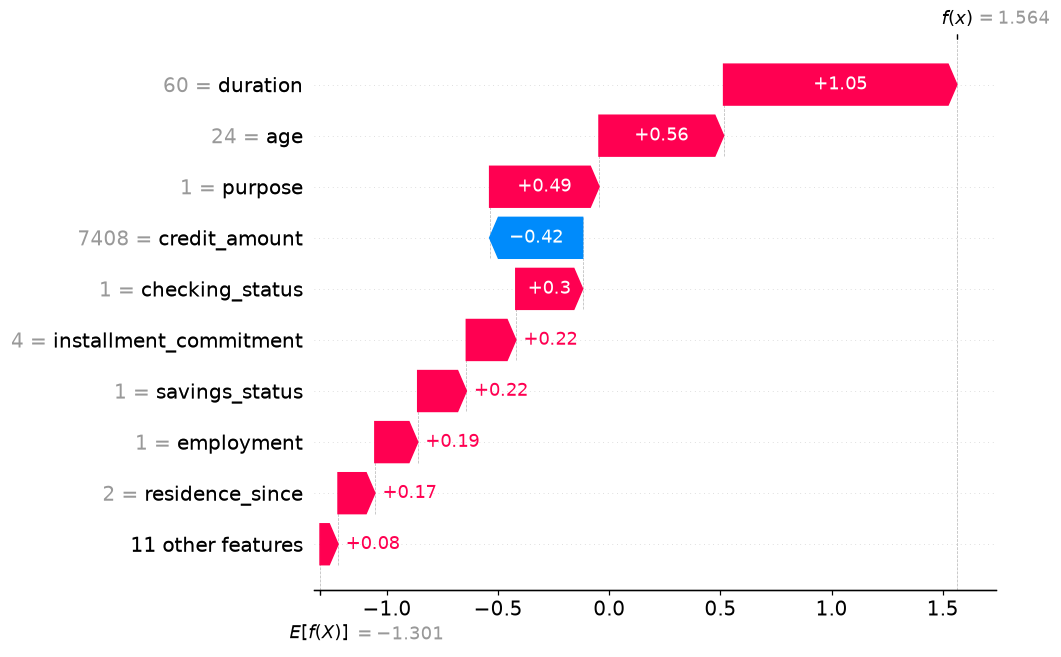

In [9]:
bg = Xtr.sample(100, random_state=0).values
tex = shap.TreeExplainer(gbm, data=bg, model_output="raw", feature_perturbation="interventional")
phi = tex.shap_values(x0[None])[0]; base = float(np.ravel(tex.expected_value)[0])
print(f"база = {base:.3f} (p = {1/(1+np.exp(-base)):.2f});  база + Σφ = {base + phi.sum():.3f};  логит f(x0) = {logit(p0):.3f}")
expl = shap.Explanation(values=phi, base_values=base, data=x0, feature_names=feat)
shap.plots.waterfall(expl, max_display=10)

**В чём измеряется.** База и $\phi$ — в логитах риска невозврата (log-odds); база $+ \sum\phi$ = логит прогноза.

### На что обращать внимание

- **Вклад — отличие от фона, а не абсолютное влияние признака.** $\phi_j$ сравнивает прогноз клиентки с прогнозами, где признак $j$ взят из фона. Здесь срок 60 месяцев даёт $+1{,}05$ логита, возраст 24 — $+0{,}56$ по сравнению со 100 случайными клиентами обучающей выборки.
- **Аддитивность выполняется в той шкале, где считали.** `TreeExplainer` раскладывает логит; в вероятностях та же разность логита даёт разный сдвиг $p$ в зависимости от точки на сигмоиде: $+1$ к логиту — это $+0{,}23$ к $p$ около $0{,}5$ и $+0{,}05$ около $0{,}03$. Делением в проценты вклады не перевести. Здесь база $-1{,}30$ ($p = 0{,}21$), база $+ \sum\phi = 1{,}56$ ($p = 0{,}83$).
- **В вклад входят взаимодействия, разделённые поровну.** Вклад признака зависит от значений остальных признаков объекта. Здесь у суммы кредита 7408 марок вклад отрицательный ($-0{,}42$) при сроке 60 месяцев.

In [10]:
backgrounds = {"все клиенты": Xtr.sample(100, random_state=0).values,
               "вернувшие кредит": Xtr[ytr == 0].sample(100, random_state=0).values,
               "клиенты 20–30 лет": Xtr[(Xtr.age >= 20) & (Xtr.age <= 30)].sample(100, random_state=0).values}
rows = {}
for name, B in backgrounds.items():
    e = shap.TreeExplainer(gbm, data=B, model_output="raw", feature_perturbation="interventional")
    ph = pd.Series(e.shap_values(x0[None])[0], index=feat)
    rows[name] = {"база": float(np.ravel(e.expected_value)[0]), **ph[["duration", "age", "credit_amount", "checking_status"]].to_dict()}
pd.DataFrame(rows).T.round(3)

,база,duration,age,credit_amount,checking_status
все клиенты,-1.301,1.049,0.561,-0.418,0.300
вернувшие кредит,-2.511,1.176,0.614,-0.162,0.602
клиенты 20–30 лет,-0.911,1.175,0.145,-0.399,0.223


**В чём измеряется.** Логиты; база — средний логит по фону.

### На что обращать внимание

- **Фон определяет, с чем сравнивают.** При той же модели и том же объекте смена фона меняет базу и вклады. Здесь вклад возраста $0{,}56$ против всех клиентов и $0{,}15$ против клиентов 20–30 лет.
- **Фон из одного класса отвечает на вопрос «чем объект отличается от этого класса».** Здесь против вернувших кредит база $-2{,}51$ вместо $-1{,}30$, вклад состояния счёта $0{,}60$ вместо $0{,}30$.
- **Без фона и режима результат не воспроизводим.** Режим `interventional` (маргинальная функция ценности на фоне) и `tree_path_dependent` (без фона, по статистике листьев) — разные функции ценности и разные ответы.

### Функция ценности задаёт игру

### Блок «Теория»

Аксиомы фиксируют, **как** делить; функция ценности $v(S)$ — **что** делим: прогноз, когда известны только признаки из $S$. Модель требует все признаки, поэтому неизвестный признак надо чем-то заменить, и способ замены — выбор автора объяснения:

| $v(S)$: чем заменяем неизвестный признак | Аналог на занятии 04 |
|---|---|
| одна точка отсчёта (baseline) | абляция |
| маргинальная: объекты фона, среднее | перестановка |
| по дереву (`tree_path_dependent`): ветки по долям обучающих объектов | — |
| условная: правдоподобные при известных | условная перестановка |

Разные $v$ — разные игры и разные значения Шепли (Sundararajan & Najmi, 2020).

### Как устроен код
```
типичный клиент ← медиана числовых признаков и самая частая категория
φ ← TreeExplainer(data = типичный клиент, interventional)   # одна точка
φ ← TreeExplainer(data = 100 клиентов, interventional)     # маргинальная
φ ← TreeExplainer(без фона, tree_path_dependent)          # по дереву
сравнить базу и вклады срока, возраста, счёта
```

In [11]:
typ = np.array(Xtr.median().values, dtype=float)[None].copy()      # типичный клиент
for c in cats: typ[0, feat.index(c)] = Xtr[c].mode()[0]
games = {"одна точка: типичный клиент": shap.TreeExplainer(gbm, data=typ, model_output="raw", feature_perturbation="interventional"),
         "маргинальная: фон 100 клиентов": shap.TreeExplainer(gbm, data=bg, model_output="raw", feature_perturbation="interventional"),
         "по дереву (path-dependent)": shap.TreeExplainer(gbm, feature_perturbation="tree_path_dependent")}
rows = {}
for name, e in games.items():
    ph = pd.Series(e.shap_values(x0[None])[0], index=feat)
    rows[name] = {"база": float(np.ravel(e.expected_value)[0]), "срок": ph.duration, "возраст": ph.age, "счёт": ph.checking_status}
print("типичный клиент:", {f: readable(feat.index(f), typ[0, feat.index(f)]) for f in ["duration", "age", "credit_amount", "checking_status"]})
pd.DataFrame(rows).T.round(2)

типичный клиент: {'duration': '18', 'age': '33', 'credit_amount': '2286', 'checking_status': 'no checking'}


,база,срок,возраст,счёт
одна точка: типичный клиент,-2.13,0.95,0.59,1.07
маргинальная: фон 100 клиентов,-1.30,1.05,0.56,0.30
по дереву (path-dependent),-1.36,1.05,0.62,0.39


**В чём измеряется.** Логиты; база — $v(\varnothing)$ в каждой игре.

### На что обращать внимание

- **Аксиомы выполняются в каждой игре, меняется вопрос.** Здесь вклад срока почти не меняется ($0{,}95$–$1{,}05$), а вклад состояния счёта — $1{,}07$ против типичного клиента, $0{,}30$ против фона и $0{,}39$ по дереву.
- **Точка отсчёта определяет, что считается отличием.** У типичного клиента расчётного счёта нет, поэтому сравнение со «счёта нет» делает счёт клиентки главным отличием.
- **Рядом со SHAP-графиком пишут функцию ценности:** точка отсчёта, фон или режим `tree_path_dependent`.

## 2.3. Kernel SHAP своими руками = LIME с ядром Шепли

### Блок «Теория»

Коалицию кодируем бинарным вектором $z \in \{0,1\}^n$ и ищем линейную модель $g(z) = \phi_0 + \sum_i \phi_i z_i$ взвешенным МНК:
$$\min_\phi \sum_z \pi(z)\big(v(z) - g(z)\big)^2, \qquad \pi(z) = \frac{n-1}{\binom{n}{|z|}\,|z|\,(n-|z|)}.$$
С таким ядром (и ограничениями $\phi_0 = v(\varnothing)$, $\sum\phi_i = v(N) - v(\varnothing)$) решение — **ровно значения Шепли** (Lundberg & Lee, 2017, теорема 2). Это постановка LIME, в которой ядро выбрано так, чтобы выполнялись аксиомы, и нет штрафа $\Omega$.

Ядро огромно у краёв ($|z|$ близко к 0 или $n$) — такие коалиции лучше всего изолируют вклад одного признака.

**TreeSHAP** (Lundberg, Erion, Lee, 2018; Lundberg et al., 2020) — точные значения Шепли для деревьев, а не приближение. $v(S)$ в одном дереве считается обходом: в узле с разбиением по признаку $j$, если $j \in S$, идём по ветке объекта; если $j \notin S$ — в обе ветки с весами, равными долям обучающих объектов (cover). Наивно нужно $2^M$ коалиций, $O(T L M 2^M)$; TreeSHAP за один обход отслеживает, какая доля всех подмножеств доходит до каждого листа, и получает $O(T L D^2)$ — $T$ деревьев, $L$ листьев, глубина $D$. Для ансамбля значения складываются по деревьям (аддитивность). Два режима: без фона (`tree_path_dependent`, веса из cover) и с фоном $R$ (`interventional`, маргинальная $v$, $O(T R L)$).

| Объяснитель `shap` | Модели | Точность | Цена |
|---|---|---|---|
| Exact | любые | точно | $2^n$ коалиций — до ~15–20 признаков |
| Permutation | любые | приближение, $\sum\phi$ точна | сэмплы порядков |
| Kernel | любые | приближение | много вызовов модели × фон |
| Tree | деревья, лес, бустинг | точно | $O(TLD^2)$; с фоном × $\lvert R\rvert$ |
| Linear | линейные | точно | закрытая формула |
| Deep / Gradient | нейросети | приближение | проходы backward |

### Как устроен код
```
сэмплировать коалиции z: размер |z| ~ ядро, признаки — случайно; брать пары (z, 1 − z)
v(z) ← средний логит модели на «лего»: признаки z от клиента, остальные от фона
учесть ограничение эффективности, исключив последний признак
φ ← МНК; сравнить с TreeSHAP при разном числе коалиций, 5 зёрен на каждое
```

In [12]:
sizes = np.arange(1, F)
v_empty, v_full = logit(f(bg)).mean(), logit(p0)
def v_of(Z):
    out = np.empty(len(Z))
    for a, z in enumerate(Z):
        A = bg.copy(); m = z.astype(bool); A[:, m] = x0[m]; out[a] = logit(f(A)).mean()
    return out
def kernel_shap(nz, seed=0):
    rg = np.random.default_rng(seed)
    pw = (F - 1) / (sizes * (F - sizes)); pw = pw / pw.sum()     # распределение размеров по ядру Шепли
    Z = np.zeros((nz // 2, F))
    for a, k in enumerate(rg.choice(sizes, nz // 2, p=pw)): Z[a, rg.choice(F, k, replace=False)] = 1
    Z = np.vstack([Z, 1 - Z])                                     # парные коалиции уменьшают дисперсию
    yv = v_of(Z) - v_empty - Z[:, -1] * (v_full - v_empty)
    sol, *_ = np.linalg.lstsq(Z[:, :-1] - Z[:, [-1]], yv, rcond=None)
    return np.append(sol, (v_full - v_empty) - sol.sum())
for nz in [32, 128, 512, 2048]:
    errs = [np.abs(kernel_shap(nz, s) - phi).max() for s in range(5)]     # 5 зёрен
    print(f"{nz:5d} коалиций: max |φ_Kernel − φ_Tree| = {np.mean(errs):.4f} ± {np.std(errs):.4f}")

   32 коалиций: max |φ_Kernel − φ_Tree| = 0.5974 ± 0.1670


  128 коалиций: max |φ_Kernel − φ_Tree| = 0.0341 ± 0.0050


  512 коалиций: max |φ_Kernel − φ_Tree| = 0.0181 ± 0.0028


 2048 коалиций: max |φ_Kernel − φ_Tree| = 0.0076 ± 0.0011


**В чём измеряется.** Максимальная по признакам абсолютная разница с TreeSHAP, в логитах; среднее и стандартное отклонение по 5 зёрнам.

### На что обращать внимание

- **Kernel SHAP — оценка с дисперсией.** Коалиции сэмплируются, разные зёрна дают разные $\phi$; ошибка убывает с числом коалиций. Здесь максимальная ошибка около 0,6 логита при 32 коалициях и меньше 0,01 при 2048.
- **Цена — число вызовов модели.** Каждая коалиция — прогноз на всём фоне: здесь 2048 коалиций × 100 объектов фона = 204 800 прогнозов на одного клиента. TreeSHAP получает точные значения за полиномиальное время, используя структуру деревьев.
- **Сэмплирование размеров по ядру заменяет веса.** Если размер коалиции выбирать с вероятностью, пропорциональной суммарному весу ядра для этого размера, взвешенный МНК становится обычным. Так устроена функция `kernel_shap` выше.

## 2.4. Линейная модель: SHAP = вес × отклонение от среднего

### Блок «Теория»

Для $f(x) = \beta_0 + \sum_j \beta_j x_j$ и маргинальной функции ценности $v(S) = \beta_0 + \sum_{j\in S}\beta_j x_j + \sum_{j\notin S}\beta_j\,\mathbb E[x_j]$ маржинальный вклад $j$ одинаков во всех коалициях, поэтому
$$\phi_j = \beta_j\big(x_j - \mathbb E[x_j]\big).$$
Это вклад $\beta_j x_j$ из занятия 03, только отсчитанный от среднего объекта. Для логистической регрессии — то же в логитах.

### Как устроен код
```
логистическая регрессия на стандартизованных признаках
φ ← LinearExplainer(модель, фон)
сравнить с β · (x − среднее фона); сравнить ROC-AUC с бустингом
```

In [13]:
sc = StandardScaler().fit(Xtr)
lr = LogisticRegression(C=1.0, max_iter=2000).fit(sc.transform(Xtr), ytr)
Bg = sc.transform(Xtr.sample(100, random_state=0)); Xs_te = sc.transform(Xte)
phi_lin = shap.LinearExplainer(lr, Bg).shap_values(Xs_te)
manual = lr.coef_[0] * (Xs_te - Bg.mean(0))
print("max |SHAP − β(x − E x)| =", np.abs(phi_lin - manual).max())
print(f"ROC-AUC логистической регрессии: {roc_auc_score(yte, lr.predict_proba(Xs_te)[:, 1]):.3f}  (бустинг: {roc_auc_score(yte, p_te):.3f})")

max |SHAP − β(x − E x)| = 0.0
ROC-AUC логистической регрессии: 0.793  (бустинг: 0.772)


**В чём измеряется.** Логиты; признаки стандартизованы. Разница с формулой — абсолютная, в логитах.

### На что обращать внимание

- **Для линейной модели SHAP — вес, умноженный на отклонение от среднего фона.** Здесь расхождение `LinearExplainer` с формулой — 0. Зависимость от фона остаётся: смена фона сдвигает $\mathbb E[x_j]$.
- **Если интерпретируемая модель не уступает по качеству, объяснять чёрный ящик не нужно** (занятие 03). Здесь ROC-AUC логистической регрессии 0,79, бустинга — 0,77.

## 2.5. От локального к глобальному

### Блок «Теория»

SHAP — локальный метод; глобальная картина собирается из локальных:
- **beeswarm (summary plot)**: точка — один клиент, по оси — $\phi_j$, цвет — значение признака;
- **dependence plot**: $\phi_j$ против $x_j$; разброс по вертикали при одинаковом $x_j$ — взаимодействия;
- **mean |SHAP|** — насколько признак в среднем двигает прогноз. Это не то же, что permutation importance (занятие 04): та измеряет, насколько падает **качество** без признака на тесте.

### Как устроен код
```
Φ ← TreeSHAP для всего теста
beeswarm(Φ); dependence(срок, цвет = сумма)
mean|Φ| против permutation importance (ROC-AUC, 20 повторов)
```

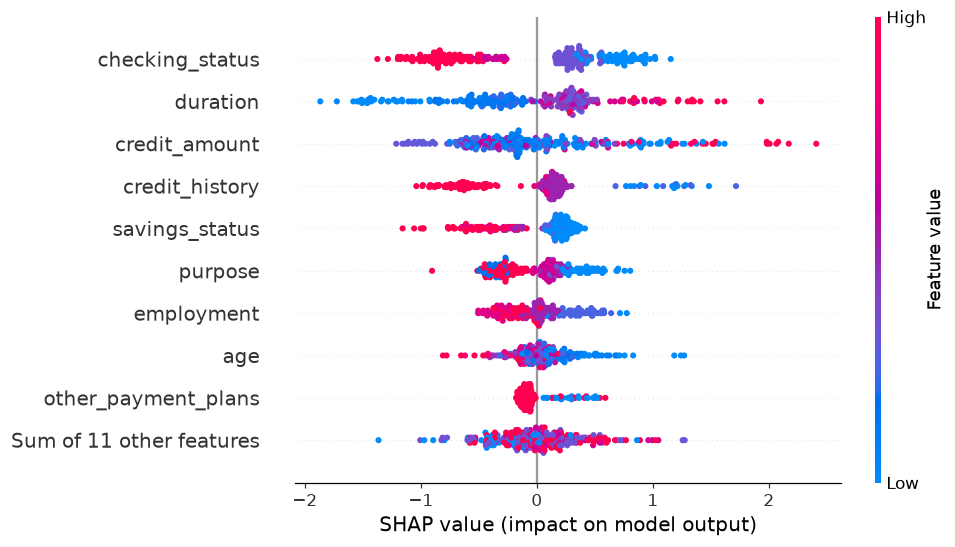

In [14]:
PH = tex(Xte.values)
PH.feature_names = feat
shap.plots.beeswarm(PH, max_display=10)

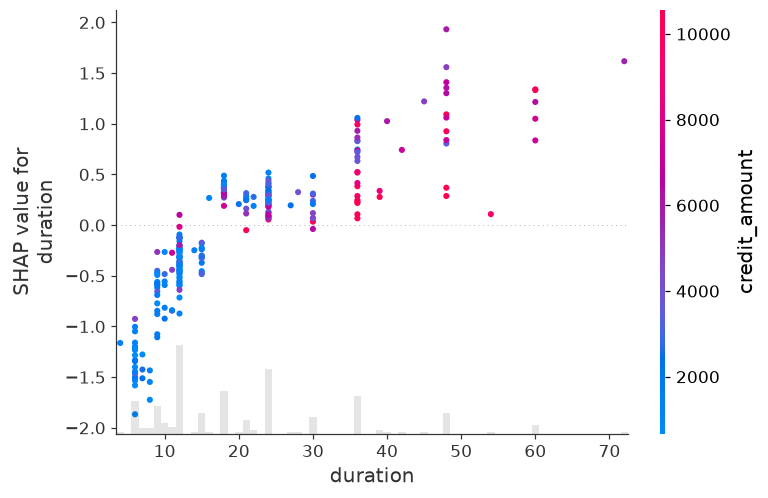

In [15]:
shap.plots.scatter(PH[:, "duration"], color=PH[:, "credit_amount"])

In [16]:
pi = permutation_importance(gbm, Xte, yte, scoring="roc_auc", n_repeats=20, random_state=0)
cmp = pd.DataFrame({"mean|SHAP|": np.abs(PH.values).mean(0), "permutation ΔAUC": pi.importances_mean}, index=feat)
cmp.sort_values("mean|SHAP|", ascending=False).round(3).head(12)

,mean|SHAP|,permutation ΔAUC
checking_status,0.607,0.097
duration,0.541,0.070
credit_amount,0.529,0.016
credit_history,0.389,0.032
savings_status,0.292,0.011
purpose,0.269,0.005
employment,0.215,0.009
age,0.189,-0.004
other_payment_plans,0.124,0.005
residence_since,0.119,0.002


**В чём измеряется.** mean|SHAP| — средний модуль вклада в логитах; permutation ΔAUC — падение ROC-AUC на тесте при перемешивании признака, безразмерное.

### На что обращать внимание

- **mean|SHAP| и permutation importance отвечают на разные вопросы.** Первая — насколько признак двигает прогнозы, вторая — насколько он нужен модели для качества на тесте (занятие 04). Здесь у возраста mean|SHAP| 0,19 и ΔAUC $-0{,}004$: модель использует признак, но на тесте это не помогает. SHAP описывает модель, а не её правоту.
- **mean|SHAP| теряет направление.** Признак, повышающий риск у одних объектов и понижающий у других, получает то же среднее, что монотонный. Направление видно на beeswarm и dependence plot.
- **Вертикальный разброс на dependence plot — взаимодействия.** При одном значении признака вклад разный, потому что зависит от остальных признаков. Здесь при одном сроке кредита вклады различаются, цвет — сумма кредита.
- **Глобальные графики — агрегаты локальных** и наследуют выбор фона, режима и шкалы.

---
# Часть 3. К нейросетям: что хранит архитектура

**LIME и SHAP применимы и к нейросетям**: им нужны только прогнозы. Меняется представление входа — у LIME для картинки суперпиксели (так в статье Ribeiro et al., 2016), для текста слова; у SHAP для картинок и текста — Partition (иерархические группы пикселей и токенов), для сетей — DeepExplainer (DeepLIFT) и GradientExplainer (expected gradients, раздел 4.3). Цена — тысячи признаков и прогон сети на каждый вызов, поэтому признаки группируют. Подробно: LIME на суперпикселях и для текста, SHAP Partition — занятие 06; Шепли по токенам и атрибуция к контексту в RAG — 10; Шепли для шагов агента — 11.

**Идеи объяснений для нейросетей:**

| Идея | Что делаем | Где |
|---|---|---|
| говорит архитектура | смотрим, что сеть хранит по построению: карты свёрток (CAM), веса внимания | часть 3 |
| говорит градиент | производная выхода по входу: saliency, gradient × input, IG, expected gradients | часть 4 |
| вмешательство во вход | портим часть входа: абляция, окклюзия, RISE, LIME на суперпикселях | занятие 06 |
| внутри модели | что объясняет устройство модели: Grad-CAM, внимание, графы, мультимодальность | занятие 07 |

Первые объяснения нейросетей берутся из того, что модель хранит по определению архитектуры: у свёрточной сети — карты признаков последнего свёрточного слоя, у трансформера — веса внимания. Они наглядны и почти ничего не стоят. Здесь — что они показывают, затем их минусы (раздел 3.4), и из минусов — переход к градиентам (часть 4).

## 3.1. Классическая карта активаций: CAM

### Блок «Теория»

**Class Activation Map** (Zhou et al., 2016) — первая карта для свёрточных сетей. В конце ResNet: последний свёрточный слой даёт $K$ карт признаков $A_k$ (у ResNet-34 — 512 карт $7\times7$), global average pooling (GAP) усредняет каждую в число, линейный слой с весами $w_k^c$ даёт логит класса $c$. Голова линейна, поэтому среднее и сумму можно переставить:
$$\mathrm{CAM}_c(h, w) = \sum_k w_k^c A_k(h, w), \qquad \text{логит}_c = \frac{1}{HW}\sum_{h,w}\mathrm{CAM}_c(h, w) + b_c.$$
CAM — **точное** разложение логита по клеткам последнего слоя, как вклад $\beta_j x_j$ в линейной модели (занятие 03).

Ограничения: нужна архитектура с GAP перед линейным слоем; разрешение $7\times7$; объясняется только последний слой. **Grad-CAM** (Selvaraju et al., 2017) заменяет $w_k^c$ усреднёнными градиентами и работает с любой CNN — занятие 07.

### Как устроен код
```
ResNet-34 (ImageNet); хук на layer4 → A: [512, 7, 7]
CAM_c ← Σ_k fc.weight[c, k] · A_k;  проверка: mean(CAM_c) + bias_c = логит_c
растянуть 7×7 до 224×224 и наложить на ровно тот кроп, который видит сеть
```

mean(CAM) + bias = 12.633;  логит = 12.633


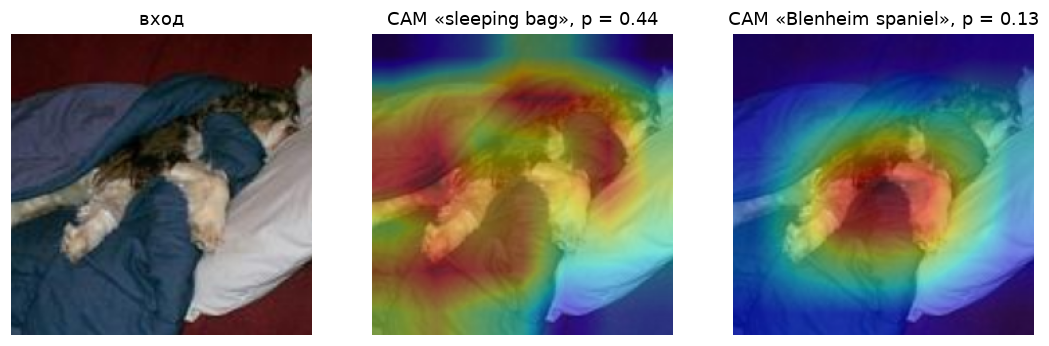

In [17]:
import torch, torchvision
from PIL import Image
wts = torchvision.models.ResNet34_Weights.IMAGENET1K_V1
cnn = torchvision.models.resnet34(weights=wts).eval(); tfm = wts.transforms(); cls_names = wts.meta["categories"]
img = Image.open("data/dog_sleeping_bag.jpg").convert("RGB")      # Imagenette, val
feats = {}
hk = cnn.layer4.register_forward_hook(lambda m, i, o: feats.__setitem__("A", o.detach()))
with torch.no_grad(): logits = cnn(tfm(img)[None])[0]
hk.remove()
A = feats["A"][0]                                                    # [512, 7, 7]
prob = logits.softmax(0); top2 = prob.topk(2).indices.tolist()
cams = {c: torch.einsum("k,khw->hw", cnn.fc.weight[c].detach(), A) for c in top2}
c0 = top2[0]
print(f"mean(CAM) + bias = {(cams[c0].mean() + cnn.fc.bias[c0]).item():.3f};  логит = {logits[c0].item():.3f}")

TF = torchvision.transforms.functional
show = np.asarray(TF.center_crop(TF.resize(img, 256), 224))        # ровно то, что видит сеть
fig, axs = plt.subplots(1, 3, figsize=(12, 4))
axs[0].imshow(show); axs[0].set_title("вход")
for ax, c in zip(axs[1:], top2):
    cm = torch.nn.functional.interpolate(cams[c][None, None], size=(224, 224), mode="bilinear")[0, 0].numpy()
    ax.imshow(show); ax.imshow((cm - cm.min()) / (cm.max() - cm.min()), cmap="jet", alpha=0.45)
    ax.set_title(f"CAM «{cls_names[c]}», p = {prob[c]:.2f}")
for ax in axs: ax.axis("off")

**В чём измеряется.** CAM — в единицах логита класса на клетку $7\times7$; на картинке нормирована в $[0, 1]$ для отображения.

### На что обращать внимание

- **CAM — точное разложение логита, но только для архитектуры с GAP и линейной головой.** Здесь mean(CAM) + bias = логит = 12,633.
- **Карта зависит от класса.** Объяснение без указания класса не определено. Здесь для «sleeping bag» ($p = 0{,}44$) подсвечено одеяло, для «Blenheim spaniel» ($p = 0{,}13$) — собака.
- **Разрешение карты — разрешение последнего свёрточного слоя.** Здесь $7\times7$ клеток на картинку $224\times224$; интерполяция не добавляет деталей. Карта для любой CNN — Grad-CAM, занятие 07.
- **Нормировка для отображения скрывает знак и масштаб.** После min–max клетки, понижающие логит, выглядят просто «холодными».

## 3.2. Карты внимания в GPT-2

### Блок «Теория»

У трансформера по определению архитектуры хранятся веса внимания. В слое трансформера каждая голова считает для токена $i$ распределение по предыдущим токенам $j \le i$ (каузальная маска):
$$A = \mathrm{softmax}\Big(\frac{QK^\top}{\sqrt{d}} + M\Big), \qquad \text{выход}_i = \sum_{j \le i} A_{ij}\, v_j W_O.$$
Строка $A_i$ — распределение (сумма 1). У GPT-2 small 12 слоёв × 12 голов = 144 карты на каждый текст.

Типичные головы: **на предыдущий токен** (позиционные), **на первый токен** (*attention sink*: когда голове «не на что смотреть», лишняя масса уходит в первую позицию — Xiao et al., 2023), **широкие** (размазанные по контексту).

**Вес ≠ вклад.** В выход входит не $A_{ij}$, а $A_{ij}\, v_j W_O$. Если у первого токена маленький вектор $v_j W_O$, большой вес почти ничего не добавляет. Норма-подход (Kobayashi et al., 2020): вклад $\lVert A_{ij}\, v_j W_O\rVert$.

### Как устроен код
```
GPT-2 с attn_implementation="eager" (иначе attentions может не вернуться)
для каждого текста: attentions → [слой, голова, T, T]
доля на предыдущий токен = среднее A[i, i−1];  на первый = среднее A[i, 0]  (i ≥ 1)
вклад по норме: перехватить V из c_attn, умножить на блок W_O головы, ‖A_ij · v_j W_O‖
```

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

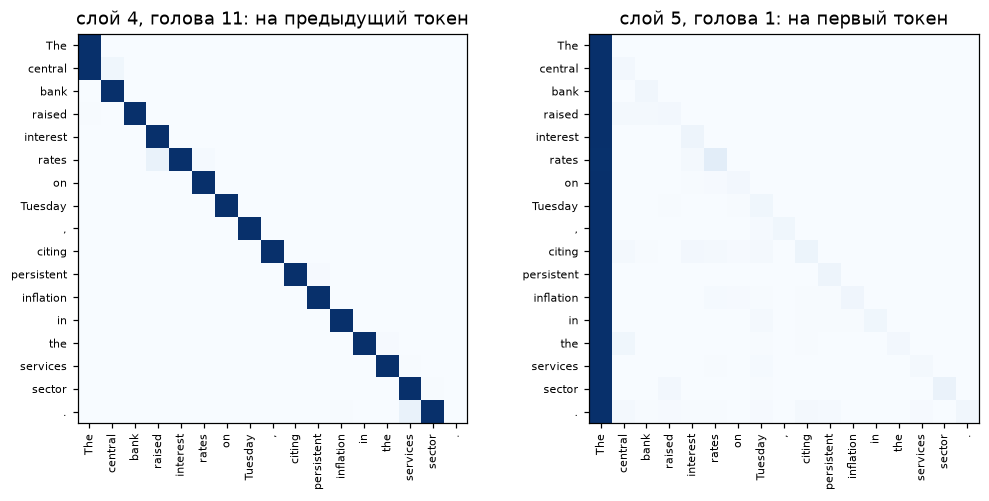

,0,1,2,3,4,5,6,7,8,9,10,11
доля на первый токен (вес),0.20,0.35,0.36,0.52,0.55,0.75,0.71,0.81,0.72,0.80,0.82,0.68
доля на первый токен (вклад по норме),0.17,0.25,0.19,0.36,0.27,0.54,0.35,0.48,0.33,0.45,0.50,0.39


In [18]:
from transformers import AutoTokenizer, GPT2Model
tok = AutoTokenizer.from_pretrained("gpt2")
gpt = GPT2Model.from_pretrained("gpt2", attn_implementation="eager").eval()
texts = ["The central bank raised interest rates on Tuesday, citing persistent inflation in the services sector.",
         "Scientists reported that the new vaccine reduced hospital admissions by half in a large clinical trial.",
         "The city council voted to close the old bridge after engineers found cracks in its main supports.",
         "Shares of the carmaker fell sharply after the company cut its sales forecast for the coming year.",
         "Local farmers say the dry summer has damaged crops and pushed up the price of vegetables.",
         "The football club announced that its coach will leave at the end of the season."]
L_, H_ = gpt.config.n_layer, gpt.config.n_head; dh = gpt.config.n_embd // H_
vals = {}
hooks = [blk.attn.c_attn.register_forward_hook(lambda m, i, o, l=l: vals.__setitem__(l, o.detach())) for l, blk in enumerate(gpt.h)]
prev, first, first_norm = np.zeros((L_, H_)), np.zeros((L_, H_)), np.zeros((L_, H_))
for k, t in enumerate(texts):
    ids = tok(t, return_tensors="pt")["input_ids"]
    with torch.no_grad(): out = gpt(input_ids=ids, output_attentions=True)
    A = torch.stack(out.attentions)[:, 0].numpy()             # [слой, голова, T, T]
    T = A.shape[-1]; idx = np.arange(1, T)
    prev += A[..., idx, idx - 1].mean(-1); first += A[..., 1:, 0].mean(-1)
    for l in range(L_):
        v = vals[l][0, :, 2 * gpt.config.n_embd:].reshape(T, H_, dh)
        Wo = gpt.h[l].attn.c_proj.weight.detach().reshape(H_, dh, -1)
        vo = torch.einsum("thd,hde->hte", v, Wo).norm(dim=-1).numpy()   # ‖v_j W_O‖ для каждой головы
        c = A[l] * vo[:, None, :]; c = c / c.sum(-1, keepdims=True)
        first_norm[l] += c[:, 1:, 0].mean(-1)
    if k == 0: A0, toks = A, [s.replace("Ġ", "") for s in tok.convert_ids_to_tokens(ids[0])]
for h in hooks: h.remove()
prev, first, first_norm = prev / len(texts), first / len(texts), first_norm / len(texts)

lp, hp = np.unravel_index(np.argmax(prev[1:]), prev[1:].shape); lp += 1
ls, hs = np.unravel_index(np.argmax(first[4:8]), (4, H_)); ls += 4
fig, axs = plt.subplots(1, 2, figsize=(11, 4.6))
for ax, (l, h, ttl) in zip(axs, [(lp, hp, "на предыдущий токен"), (ls, hs, "на первый токен")]):
    ax.imshow(A0[l, h] ** 0.5, cmap="Blues"); ax.set_title(f"слой {l}, голова {h}: {ttl}")
    ax.set_xticks(range(len(toks))); ax.set_xticklabels(toks, rotation=90, fontsize=7); ax.set_yticks(range(len(toks))); ax.set_yticklabels(toks, fontsize=7)
plt.show()
pd.DataFrame({"доля на первый токен (вес)": first.mean(1), "доля на первый токен (вклад по норме)": first_norm.mean(1)}).round(2).T

**В чём измеряется.** Вес внимания — доля от 0 до 1, строка карты суммируется в 1. Доля по норме — доля $\lVert A_{ij}\, v_j W_O\rVert$ в сумме по $j$.

### На что обращать внимание

- **Часть голов реализует позиционные паттерны, не зависящие от смысла текста.** Здесь на рисунке — голова, почти целиком смотрящая на предыдущий токен, и голова, отдающая почти всё первому токену.
- **Вес ≠ вклад.** В выход головы входит $A_{ij}\, v_j W_O$; при малой норме $v_j W_O$ большой вес мало что добавляет. Здесь в слоях 7–10 на первый токен приходится 0,72–0,82 весов, но 0,33–0,50 вклада по норме.
- **Вклад по норме относится к выходу одного слоя.** Дальше residual, MLP и следующие слои. Для всей модели — rollout (Abnar & Zuidema, 2020), градиенты, абляции; занятия 07 и 10.
- **Внимание — часть вычисления, а не мера важности входа** (Jain & Wallace, 2019; Wiegreffe & Pinter, 2019).

## 3.3. Как сравнить две карты внимания: частный пример JS-дивергенция

### Блок «Теория»

Частая задача — сравнить внимание двух моделей или на двух текстах. Строка карты — распределение, поэтому сравнивают распределения. **Один из способов** — дивергенция Дженсена — Шеннона (другие способы сравнивать внимание и атрибуции для текста — на занятии 07):
$$\mathrm{JS}(p\,\|\,q) = \tfrac12\mathrm{KL}(p\,\|\,m) + \tfrac12\mathrm{KL}(q\,\|\,m), \quad m = \tfrac12(p + q), \qquad \mathrm{KL}(p\,\|\,m) = \sum_j p_j \log_2\frac{p_j}{m_j}.$$
С $\log_2$ значение лежит в $[0, 1]$: 0 — распределения совпадают, 1 — у них нет общих токенов.

Обратите внимание — это просто частный пример оценки. 

### Как устроен код
```
m ← (p + q) / 2
JS ← ½ KL(p ‖ m) + ½ KL(q ‖ m), логарифм по основанию 2
сравнить с scipy.spatial.distance.jensenshannon(p, q, base=2)
```

In [19]:
def js_div(p, q, eps=1e-12):
    m = 0.5 * (p + q)
    kl = lambda a, b: (a * (np.log2(a + eps) - np.log2(b + eps))).sum(-1)
    return 0.5 * kl(p, m) + 0.5 * kl(q, m)
from scipy.spatial.distance import jensenshannon
p = np.array([0.70, 0.05, 0.10, 0.05, 0.10]); q = np.array([0.25, 0.10, 0.35, 0.10, 0.20])
print(f"JS = {js_div(p, q):.3f};  scipy jensenshannon(base=2) = {jensenshannon(p, q, base=2):.3f} = √JS = {np.sqrt(js_div(p, q)):.3f}")

JS = 0.158;  scipy jensenshannon(base=2) = 0.397 = √JS = 0.397


**В чём измеряется.** JS с $\log_2$ — в битах, от 0 до 1.

### На что обращать внимание

- **`scipy.spatial.distance.jensenshannon` возвращает корень из JS** — расстояние, а не дивергенцию. Здесь JS $= 0{,}158$, scipy даёт $0{,}397 = \sqrt{0{,}158}$.
- **Первую строку каузальной карты исключают:** токен 0 видит только себя, JS там всегда 0.
- **Изменения внимания копятся с глубиной.** Карта слоя $l$ меняется и при неизменных весах этого слоя, если изменился вход из нижних слоёв.
- **JS — одна из многих метрик сравнения.** Строки карт сравнивают и KL, и косинусом, и корреляцией; лучшей нет — метрику выбирают под задачу.
- **Сравнение карт само по себе мало что даёт на практике** — разве что когда вы вмешиваетесь в модель на инференсе и ищете, куда вмешаться.
- **Изменение карты внимания ≠ изменение важности входа** (раздел 3.2).

## 3.4. Минусы объяснений из устройства архитектуры

| Минус | CAM | Карта внимания |
|---|---|---|
| Привязка к архитектуре | нужны global average pooling и линейная голова | есть только у трансформеров |
| Один слой | последний свёрточный слой | одна голова одного слоя; дальше residual, MLP, остальные слои |
| Не вклад входа в выход модели | точное разложение только логита через линейную голову | вес ≠ вклад даже в своём слое: в слоях 7–10 GPT-2 на первый токен 0,72–0,82 веса и 0,33–0,50 вклада по норме (раздел 3.2) |
| Грубость и выбор | разрешение $7\times7$ | у GPT-2 small 144 карты на текст — какую смотреть, решает исследователь |

У маленькой полносвязной сети на German Credit (часть 4) нет ни свёрток, ни внимания — эти объяснения к ней не применимы.

Отсюда переход: нужен метод для любой дифференцируемой модели, который объясняет выход всей модели через вход. Это градиенты.

---
# Часть 4. Градиенты: объяснение всей модели через вход

## 4.1. LIME при сужении окрестности — это градиент

### Блок «Теория»

Методу нужна только **дифференцируемость** модели — особая архитектура не требуется. Разложение Тейлора в точке $x$:
$$f(x + \delta) \approx f(x) + \nabla f(x)^\top \delta.$$
LIME подгоняет линейную модель к $f$ в окрестности $x$. Если окрестность сжимать ($\varepsilon \to 0$), лучшая линейная модель — касательная плоскость, а её веса — **градиент** $\nabla f(x)$. Градиент считается одним обратным проходом — вместо тысяч вызовов модели.

**Как считается градиент.** Сеть — композиция слоёв: $h_1 = \tanh(W_1 x + b_1)$, $h_2 = \tanh(W_2 h_1 + b_2)$, $f = W_3 h_2 + b_3$. По цепному правилу, с $\tanh'(u) = 1 - \tanh^2(u)$:
$$\nabla_x f = W_1^\top\,\mathrm{diag}\big(1 - h_1^2\big)\,W_2^\top\,\mathrm{diag}\big(1 - h_2^2\big)\,W_3^\top.$$
Обратный проход (backpropagation) вычисляет это произведение справа налево — от выхода к входу, переиспользуя активации $h_1, h_2$ из прямого прохода. Стоимость — порядка одного прямого прохода, независимо от числа признаков $d$. Конечные разности требуют $d + 1$ прогонов (центральные — $2d$), LIME — тысячи сэмплов.

**Saliency map** — $|\partial f / \partial x_j|$: насколько чувствителен прогноз к каждому признаку (Simonyan et al., 2014). Gradient × input — в разделе 4.2.

**Модель.** Чтобы был градиент, обучим на тех же данных маленькую сеть: 20 → 16 → 16 → 1, tanh, признаки стандартизованы.

### Как устроен код
```
MLP ← обучить на стандартизованных признаках (AdamW, weight decay)
grad ← ∂ логит / ∂x в точке клиентки (один backward)
для ε в [3 … 0.03]:
    z ← x + ε·N(0, I);  веса ← МНК логита на (z − x)
    cos(веса, grad)
проверка: grad по цепному правилу вручную и центральными разностями против autograd
```

In [20]:
import torch, torch.nn as nn
torch.manual_seed(0)
scm = StandardScaler().fit(Xtr)
T_tr = torch.tensor(scm.transform(Xtr), dtype=torch.float32); T_te = torch.tensor(scm.transform(Xte), dtype=torch.float32)
net = nn.Sequential(nn.Linear(F, 16), nn.Tanh(), nn.Linear(16, 16), nn.Tanh(), nn.Linear(16, 1))
opt = torch.optim.AdamW(net.parameters(), lr=3e-3, weight_decay=1e-2)
yt_ = torch.tensor(ytr, dtype=torch.float32)
for _ in range(120):
    opt.zero_grad(); nn.functional.binary_cross_entropy_with_logits(net(T_tr).squeeze(1), yt_).backward(); opt.step()
net.eval()
g_net = lambda a: net(a).squeeze(-1)                      # выход — логит
def net_np(Z):
    with torch.no_grad(): return g_net(torch.tensor(np.asarray(Z), dtype=torch.float32)).numpy()
xs = T_te[I0:I0 + 1]; xs_np = xs[0].numpy()
print(f"ROC-AUC MLP: {roc_auc_score(yte, net_np(T_te.numpy())):.3f};  p клиентки = {torch.sigmoid(g_net(xs)).item():.3f}")

xr = xs.clone().requires_grad_(True); g_net(xr).sum().backward(); grad = xr.grad[0].numpy()
rg = np.random.default_rng(0)
for eps in [3, 1, 0.5, 0.1, 0.03]:
    Z = xs_np + eps * rg.normal(size=(4000, F))
    b = np.linalg.lstsq(np.c_[np.ones(len(Z)), Z - xs_np], net_np(Z), rcond=None)[0][1:]
    print(f"ε = {eps:4}: cos(веса LIME, градиент) = {b @ grad / np.linalg.norm(b) / np.linalg.norm(grad):.3f}")

ROC-AUC MLP: 0.821;  p клиентки = 0.883
ε =    3: cos(веса LIME, градиент) = 0.778
ε =    1: cos(веса LIME, градиент) = 0.922
ε =  0.5: cos(веса LIME, градиент) = 0.990
ε =  0.1: cos(веса LIME, градиент) = 1.000
ε = 0.03: cos(веса LIME, градиент) = 1.000


In [21]:
W1, b1 = net[0].weight.detach().numpy(), net[0].bias.detach().numpy()
W2, b2 = net[2].weight.detach().numpy(), net[2].bias.detach().numpy()
W3 = net[4].weight.detach().numpy()[0]
h1 = np.tanh(W1 @ xs_np + b1); h2 = np.tanh(W2 @ h1 + b2)              # прямой проход
grad_chain = W1.T @ ((1 - h1 ** 2) * (W2.T @ ((1 - h2 ** 2) * W3)))      # обратный: справа налево
hh = 1e-3
grad_fd = np.array([(net_np((xs_np + hh * e)[None])[0] - net_np((xs_np - hh * e)[None])[0]) / (2 * hh) for e in np.eye(F)])
print(f"max |цепное правило − autograd| = {np.abs(grad_chain - grad).max():.1e}")
print(f"max |конечные разности − autograd| = {np.abs(grad_fd - grad).max():.1e}")
print(f"вызовов модели: backward — 1, центральные разности — {2 * F}, LIME — 4000 на одно ε")

max |цепное правило − autograd| = 6.0e-08
max |конечные разности − autograd| = 2.1e-04
вызовов модели: backward — 1, центральные разности — 40, LIME — 4000 на одно ε


**В чём измеряется.** Косинус между вектором весов LIME и градиентом логита, от $-1$ до 1. Проверка градиента — максимальная абсолютная разница, в логитах на единицу стандартизованного признака.

### На что обращать внимание

- **Градиент — предел LIME при сужении окрестности.** Здесь косинус 0,78 при $\varepsilon = 3$ и 1,00 при $\varepsilon \le 0{,}1$.
- **Градиент описывает только бесконечно малую окрестность.** У него те же ограничения, что у LIME с узким ядром; в насыщенной области нелинейности он мал, даже если признак сильно сдвигает прогноз (раздел 4.3).
- **Обратный проход — то же цепное правило, вычисленное справа налево.** Здесь градиент, собранный вручную из весов и активаций, совпадает с autograd до $6 \cdot 10^{-8}$; центральные разности — до $2 \cdot 10^{-4}$ (ошибка шага и float32).
- **Градиент дешевле, но требует дифференцируемой модели.** Здесь один обратный проход против 40 прогонов центральных разностей и 4000 сэмплов LIME на каждое $\varepsilon$; к деревьям не применим.

## 4.2. Gradient × Input

### Блок «Теория»

**Определение.** Вклад признака $j$ — значение признака, умноженное на производную модели по нему в точке объекта:
$$a_j(x) = x_j\,\frac{\partial f(x)}{\partial x_j}.$$
**Откуда берётся.** Тейлор первого порядка в точке $x$, вычисленный в нуле: $f(0) \approx f(x) - \sum_j x_j\,\partial f(x)/\partial x_j$, то есть
$$f(x) - f(0) \approx \sum_j x_j\,\frac{\partial f(x)}{\partial x_j}.$$
Каждое слагаемое — приближённый вклад признака в отличие прогноза от прогноза в нуле.

- Для линейной модели $\partial f/\partial x_j = \beta_j$, и G×I — **ровно** вклад $\beta_j x_j$ (занятие 03).
- Для сетей, где все нелинейности — ReLU, совпадает с ε-LRP (Ancona et al., 2018).
- IG с baseline 0 — тот же $x \cdot$ градиент, но градиент **усреднён по пути** от 0 до $x$ (раздел 4.3).

**Две проблемы:** градиент взят в одной точке (насыщение → нет полноты), а baseline 0 неявный — смысл нуля зависит от того, как закодированы признаки.

### Как устроен код
```
G×I в стандартизованных признаках:  x_std · ∂f/∂x_std          (0 = средний клиент)
G×I в сырых единицах:               x_raw · ∂f/∂x_raw = x_raw · ∂f/∂x_std / σ   (0 = «нулевой» клиент)
сравнить суммы с f(x) − f(0) и между собой
```

In [22]:
zero = torch.zeros_like(xs)                               # 0 после стандартизации = средний клиент
gz = grad * xs_np                                          # стандартизованные признаки
x_raw = xs_np * scm.scale_ + scm.mean_
gr = (grad / scm.scale_) * x_raw                           # та же модель, сырые единицы
zero_raw = torch.tensor(((0 - scm.mean_) / scm.scale_)[None], dtype=torch.float32)
print(f"стандартизованные: Σ G×I = {gz.sum():.2f};  f(x) − f(среднего) = {(g_net(xs) - g_net(zero)).item():.2f}")
print(f"сырые единицы:     Σ G×I = {gr.sum():.2f};  f(x) − f(нулей)    = {(g_net(xs) - g_net(zero_raw)).item():.2f}")
print(f"ранговая корреляция двух вариантов: {pd.Series(gz).corr(pd.Series(gr), method='spearman'):.2f}")
pd.DataFrame({"G×I (std)": gz, "G×I (сырые)": gr, "x_raw": x_raw}, index=feat).loc[["duration", "installment_commitment", "purpose", "personal_status"]].round(3)

стандартизованные: Σ G×I = 1.20;  f(x) − f(среднего) = 3.88
сырые единицы:     Σ G×I = 3.02;  f(x) − f(нулей)    = 1.84
ранговая корреляция двух вариантов: 0.19


,G×I (std),G×I (сырые),x_raw
duration,-0.267,-0.410,60.0
installment_commitment,0.591,2.285,4.0
purpose,0.394,-0.128,1.0
personal_status,0.151,0.000,-0.0


**В чём измеряется.** Логиты риска. В стандартизованном варианте ноль — средний клиент, в сыром — объект со всеми признаками, равными нулю.

### На что обращать внимание

- **Нет полноты.** Сумма G×I равна $f(x) - f(0)$, только если модель линейна на отрезке от 0 до $x$. Здесь $\sum$ G×I $= 1{,}20$ при $f(x) - f(0) = 3{,}88$ (стандартизованные) и $3{,}02$ при $1{,}84$ (сырые единицы).
- **Неявный baseline 0 зависит от кодировки признаков.** Здесь одна модель и одна точка, а ранговая корреляция двух вариантов 0,19; у цели кредита знак меняется ($+0{,}39 \to -0{,}13$); «пол и семья» в сырых единицах получает 0, потому что код категории у клиентки — 0.
- **Точен только для линейной модели;** равенство с ε-LRP требует ReLU-сети. Здесь сеть с tanh — к ней оно не применимо. IG (раздел 4.3) задаёт путь и baseline явно.

## 4.3. Integrated Gradients и expected gradients — SHAP для сетей

### Блок «Теория»

Градиент локален: если признак «насытился» (tanh в плоской части), градиент около нуля, хотя признак мог сильно сдвинуть прогноз. **Integrated Gradients** (Sundararajan et al., 2017) интегрируют градиент вдоль прямой от **baseline** $x'$ до $x$:
$$\mathrm{IG}_j(x) = (x_j - x'_j)\int_0^1 \frac{\partial f\big(x' + \alpha(x - x')\big)}{\partial x_j}\,d\alpha.$$
- **Полнота (completeness):** $\sum_j \mathrm{IG}_j = f(x) - f(x')$ — та же аксиома эффективности, что у SHAP.
- IG — это значение **Аумана — Шепли**: непрерывный аналог Шепли для «игры», где каждый признак входит постепенно.
- **Baseline** — тот же вопрос «по сравнению с кем?», что фон в SHAP.

**Expected gradients** (Erion et al., 2021; `shap.GradientExplainer`). IG отвечает «по сравнению с одной точкой $x'$», и эта точка произвольна. EG берут baseline из фоновой выборки и усредняют IG:
$$\mathrm{EG}_j(x) = \mathbb E_{x' \sim \text{фон}}\big[\mathrm{IG}_j(x; x')\big], \qquad \sum_j \mathrm{EG}_j = f(x) - \mathbb E_{x' \sim \text{фон}}\big[f(x')\big].$$
Полнота в среднем — это эффективность SHAP с той же базой $\phi_0$: EG отвечают на вопрос маргинального SHAP «по сравнению с фоном». Для линейной модели совпадение точное: $\mathrm{EG}_j = \beta_j(x_j - \mathbb E x_j)$ — формула из раздела про линейную модель; для сети это приближение. Считают Монте-Карло: случайный объект фона и случайное $\alpha$, один обратный проход на пару. DeepLIFT / DeepSHAP — ещё одно быстрое приближение через модифицированный backward.

### Как устроен код
```
IG(x, x') ← (x − x') · среднее градиентов в 64 точках на отрезке x' → x
проверка полноты: Σ IG = f(x) − f(x')
EG ← среднее IG по 100 фоновым объектам
SHAP ← PermutationExplainer на том же фоне; сравнить с IG, EG, grad × input
```

In [23]:
def ig(x, base, m=64):
    al = torch.linspace(0, 1, m + 1)[1:].unsqueeze(1)
    pts = (base + al * (x - base)).requires_grad_(True); g_net(pts).sum().backward()
    return ((x - base) * pts.grad.mean(0)).squeeze(0).detach().numpy()

zero = torch.zeros_like(xs)                               # 0 после стандартизации = средний клиент
ig0 = ig(xs, zero)
print(f"Σ IG = {ig0.sum():.3f};  f(x) − f(baseline) = {(g_net(xs) - g_net(zero)).item():.3f}")

bgn = scm.transform(Xtr.sample(100, random_state=0)).astype(np.float32)
eg = np.mean([ig(xs, torch.tensor(b[None]), 32) for b in bgn], 0)
sv_net = shap.PermutationExplainer(net_np, shap.maskers.Independent(bgn, max_samples=100), seed=0)(xs_np[None], max_evals=4000).values[0]
cmp = pd.DataFrame({"SHAP": sv_net, "expected grad": eg, "IG (0)": ig0, "grad×input": grad * xs_np}, index=feat)
print(cmp.corr().loc["SHAP"].round(3).to_string())
cmp.reindex(cmp.SHAP.abs().sort_values(ascending=False).index).head(7).round(3)

Σ IG = 3.832;  f(x) − f(baseline) = 3.880


SHAP             1.000
expected grad    0.983
IG (0)           0.973
grad×input       0.431


,SHAP,expected grad,IG (0),grad×input
duration,0.740,0.670,0.845,-0.267
installment_commitment,0.463,0.542,0.653,0.591
credit_amount,0.426,0.462,0.517,0.203
purpose,0.402,0.468,0.533,0.394
personal_status,0.300,0.312,0.396,0.151
employment,0.278,0.296,0.380,0.136
credit_history,0.249,0.277,0.319,0.085


**В чём измеряется.** Логиты; SHAP и EG — вклады в отличие логита от среднего по фону, IG — от логита в baseline 0 (средний клиент).

### На что обращать внимание

- **Полнота — проверка реализации.** Остаток — ошибка численного интеграла, он убывает с числом шагов. Здесь $\sum$ IG $= 3{,}83$ при $f(x) - f(x') = 3{,}88$ на 64 шагах.
- **Ответ зависит от baseline.** IG с одним baseline отвечает «по сравнению с этой точкой», expected gradients — «по сравнению с фоном», как маргинальный SHAP. Здесь корреляция с SHAP: expected gradients 0,98, IG с baseline 0 — 0,97.
- **Градиент в одной точке не учитывает насыщение.** Здесь у срока кредита grad × input $-0{,}27$ при SHAP $+0{,}74$ и IG $+0{,}85$; корреляция grad × input с SHAP 0,43.
- **Цена растёт с надёжностью.** Здесь grad × input — один обратный проход, IG с одним baseline — 64, expected gradients — 100 baseline × 32 шага = 3200.
- **Выбор baseline для изображений и текста** — занятие 06.

---
# Итог

| | LIME | SHAP | CAM, attention | Градиенты (IG, EG) |
|---|---|---|---|---|
| Вопрос | какая простая модель похожа на $f$ рядом с $x$? | как разделить $f(x) - \mathbb E f$? | что хранит архитектура: карты свёрток, веса внимания | как разделить $f(x) - f(x')$ для дифференцируемой модели |
| Гарантии | нет | аксиомы для выбранной $v$ | CAM — разложение логита по клеткам; attention — никаких для входа | полнота: $\sum = f(x) - f(x')$ |
| Ваши решения | ядро, $\sigma$, представление, $K$ | фон, режим, шкала | класс, слой, голова, вес или норма вклада | baseline, число шагов |
| Типичная ошибка | читать без R² и повторных запусков | читать как причину или «что менять» | читать вес внимания как важность входа | grad × input вместо IG; забыть про baseline |

**Один клиент — разные вопросы.**

| Метод | Вопрос | Ответ на клиентке |
|---|---|---|
| LIME | какая простая модель ведёт себя так же рядом? | лидер — срок или возраст, зависит от представления; R² суррогата 0,20–0,41 |
| SHAP | как разделить прогноз между признаками? | срок $+1{,}05$, возраст $+0{,}56$ логита — по сравнению с фоном |
| CAM, attention | что хранит архитектура сети? | к табличной модели неприменимы |
| градиенты, IG | как разделить прогноз сети через вход? | срок $+0{,}85$ (IG); expected gradients ≈ SHAP |
| контрфактуал (занятие 04) | что изменить, чтобы одобрили? | минимальное изменение, при котором решение меняется |

**Где увидим другие идеи.**

| Занятие | Что появится |
|---|---|
| 06 · вход | что считать признаком и чем его заменить — на картинках, тексте, рядах, аудио, графах и в рекомендациях: окклюзия, RISE, LIME на суперпикселях, leave-one-out; градиент, SmoothGrad, baseline для IG |
| 07 · внутри модели | Grad-CAM, внимание и attention rollout, графы (GNNExplainer), мультимодальность (CLIP) |
| 08 · оценка объяснений | deletion / insertion, ROAR, sanity checks; необходимость и достаточность |
| 09 · хрупкость и атаки | расхождение методов, Рашомон, атаки на LIME и SHAP, манипуляция картами |
| 10 · прикладной анализ LLM | атрибуция к контексту в RAG, самообъяснения, probes, steering, словари SAE |
| 11 · агенты | атрибуция ошибок в траекториях, AgentSHAP, контрфактуалы |

**Общее правило:** все методы отвечают на вопросы о *модели* при выбранных допущениях. Указывайте эти допущения рядом с объяснением.

**Связь с занятием 04.** Там методы извлекали характеристики признаков без требований к самому методу. Здесь SHAP и IG заданы аксиомами (эффективность, полнота), но аксиомы гарантируют честный делёж только для выбранной функции ценности — фона или baseline. Это тот же вопрос, что у перестановки: чем заменить признак.

## Литература
- Ribeiro, Singh, Guestrin. «Why should I trust you?» Explaining the predictions of any classifier. KDD 2016.
- Knab, Marton, Schlegel, Bartelt. Which LIME should I trust? Concepts, challenges, and solutions. xAI 2025 (arXiv:2503.24365).
- Shapley. A value for n-person games. 1953. Lundberg & Lee. A unified approach to interpreting model predictions. NeurIPS 2017.
- Lundberg et al. From local explanations to global understanding with explainable AI for trees. Nature Machine Intelligence, 2020.
- Chen, Janizek, Lundberg, Lee. True to the model or true to the data? 2020. Janzing, Minorics, Blöbaum. Feature relevance quantification in explainable AI: a causal problem. AISTATS 2020.
- Covert, Lundberg, Lee. Explaining by removing. JMLR 2021.
- Simonyan, Vedaldi, Zisserman. Deep inside convolutional networks. 2014. Ancona et al. Towards better understanding of gradient-based attribution methods. ICLR 2018. Zhou et al. Learning deep features for discriminative localization (CAM). CVPR 2016. Selvaraju et al. Grad-CAM. ICCV 2017. Sundararajan, Taly, Yan. Axiomatic attribution for deep networks (Integrated Gradients). ICML 2017.
- Lundberg, Erion, Lee. Consistent individualized feature attribution for tree ensembles. arXiv:1802.03888, 2018. Sundararajan & Najmi. The many Shapley values for model explanation. ICML 2020.
- Erion et al. Improving performance of deep learning models with axiomatic attribution priors and expected gradients. Nature Machine Intelligence, 2021. Shrikumar et al. DeepLIFT. ICML 2017.
- Jain & Wallace. Attention is not explanation. NAACL 2019. Wiegreffe & Pinter. Attention is not not explanation. EMNLP 2019.
- Kobayashi et al. Attention is not only a weight: analyzing transformers with vector norms. EMNLP 2020. Abnar & Zuidema. Quantifying attention flow in transformers. ACL 2020.
- Xiao et al. Efficient streaming language models with attention sinks. ICLR 2024.
- Stepik-курс «Интерпретируемые модели AI», модуль «Методы объяснений»; туториал `XAI-open_materials/LIME`.